# Análise exploratória de uma carteira fictícia de crédito PJ

**Objetivo:** demonstrar organização de dados, análise exploratória e comunicação de conclusões de negócio com Python.

**Pergunta central:** quais características estão associadas à deterioração de uma carteira fictícia de crédito para empresas?

> **Importante:** todos os registros deste notebook são sintéticos, gerados por código e com finalidade didática. Não representam clientes, operações bancárias nem resultados do processo seletivo original. As relações observadas decorrem das regras usadas para simular os dados e não devem ser interpretadas como evidência sobre o mercado real.

## Roteiro
1. Gerar uma base reproduzível e entender suas variáveis.
2. Auditar a qualidade dos dados e tratar ausências com regras explícitas.
3. Criar indicadores financeiros simples.
4. Comparar grupos e visualizar padrões.
5. Resumir achados e limitações sem afirmar causalidade.

## 1. Bibliotecas e configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMENTE = 20261023
N_EMPRESAS = 1500
rng = np.random.default_rng(SEMENTE)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"
print(f"Semente: {SEMENTE} | Registros sintéticos: {N_EMPRESAS:,}")

Semente: 20261023 | Registros sintéticos: 1,500


## 2. Geração da base sintética

As distribuições e relações abaixo foram escolhidas apenas para criar um exemplo didático analisável. A variável `cliente_em_deterioracao` é simulada a partir de uma probabilidade construída com alguns indicadores; portanto, o notebook serve para demonstrar o fluxo de análise, não para validar uma hipótese empírica real.

In [2]:
estados = np.array(["SP", "MG", "RJ", "PR", "RS", "BA", "SC", "GO"])
setores = np.array(["Comércio", "Indústria", "Serviços", "Construção", "Agronegócio"])
portes = np.array(["Micro", "Pequena", "Média", "Grande"])

estado = rng.choice(estados, N_EMPRESAS, p=[.28, .15, .12, .12, .10, .09, .08, .06])
setor = rng.choice(setores, N_EMPRESAS, p=[.29, .18, .27, .12, .14])
porte = rng.choice(portes, N_EMPRESAS, p=[.33, .32, .23, .12])

fator_porte = pd.Series(porte).map({"Micro": 1.0, "Pequena": 3.0, "Média": 10.0, "Grande": 35.0}).to_numpy()
faturamento = rng.lognormal(mean=10.0, sigma=.75, size=N_EMPRESAS) * fator_porte
faturamento = np.clip(faturamento, 8_000, 15_000_000)

endividamento_pct = np.clip(rng.gamma(2.2, 32, N_EMPRESAS), 5, 220)
divida_total = faturamento * endividamento_pct / 100 * rng.uniform(0.6, 1.5, N_EMPRESAS)
saldo_medio_cc = faturamento * rng.beta(1.8, 10, N_EMPRESAS)
saldo_custodia = faturamento * rng.beta(1.2, 16, N_EMPRESAS)
movimentacao = faturamento * rng.uniform(.25, 1.35, N_EMPRESAS)
volume_antecipado = movimentacao * rng.beta(1.4, 4.0, N_EMPRESAS)
utilizacao_limite = np.clip(rng.normal(62, 23, N_EMPRESAS), 0, 100)

# Atrasos simulados: empresas com maior utilização e maior dívida/faturamento
# recebem uma distribuição de atraso um pouco mais elevada.
pressao_financeira = (endividamento_pct > 90).astype(float) + (utilizacao_limite > 85).astype(float)
prob_atraso = np.clip(.10 + .10 * pressao_financeira, .05, .50)
dias_atraso_atual = np.where(rng.random(N_EMPRESAS) < prob_atraso,
                             rng.choice([5, 15, 30, 60, 90], N_EMPRESAS, p=[.25, .25, .22, .18, .10]), 0)
pior_atraso_12m = np.maximum(dias_atraso_atual, rng.choice([0, 0, 0, 15, 30, 60, 90], N_EMPRESAS))
valor_garantia = divida_total * rng.uniform(.0, 1.5, N_EMPRESAS)
cobertura_garantia = np.divide(valor_garantia, divida_total, out=np.full(N_EMPRESAS, np.nan), where=divida_total != 0) * 100

# Rótulo sintético construído para fins didáticos; não é uma inadimplência observada.
logit = (-2.1 + .95 * (endividamento_pct > 90) + .85 * (utilizacao_limite > 85)
         + .9 * (dias_atraso_atual > 0) - .45 * (cobertura_garantia > 80)
         + .25 * (volume_antecipado / np.maximum(movimentacao, 1) > .55))
prob_deterioracao = 1 / (1 + np.exp(-logit))
cliente_em_deterioracao = (rng.random(N_EMPRESAS) < prob_deterioracao).astype(int)

dados = pd.DataFrame({
    "estado": estado,
    "setor_atividade": setor,
    "porte_empresa": porte,
    "faturamento_mensal_r$": faturamento.round(2),
    "divida_total_r$": divida_total.round(2),
    "saldo_medio_cc_r$": saldo_medio_cc.round(2),
    "saldo_custodia_r$": saldo_custodia.round(2),
    "movimentacao_mensal_cc_r$": movimentacao.round(2),
    "volume_antecipado_r$": volume_antecipado.round(2),
    "utilizacao_limite_pct": utilizacao_limite.round(2),
    "dias_atraso_atual": dias_atraso_atual,
    "pior_atraso_12m_dias": pior_atraso_12m,
    "cobertura_garantia_pct": cobertura_garantia.round(2),
    "cliente_em_deterioracao": cliente_em_deterioracao,
})

# Introduz ausências artificiais para demonstrar a auditoria e o tratamento.
for coluna, percentual in {
    "faturamento_mensal_r$": .03,
    "saldo_custodia_r$": .05,
    "pior_atraso_12m_dias": .04,
    "cobertura_garantia_pct": .06,
}.items():
    indices = rng.choice(dados.index, size=int(percentual * len(dados)), replace=False)
    dados.loc[indices, coluna] = np.nan

print("Dimensão da base:", dados.shape)
display(dados.head())

Dimensão da base: (1500, 14)


,estado,setor_atividade,porte_empresa,faturamento_mensal_r$,divida_total_r$,saldo_medio_cc_r$,saldo_custodia_r$,movimentacao_mensal_cc_r$,volume_antecipado_r$,utilizacao_limite_pct,dias_atraso_atual,pior_atraso_12m_dias,cobertura_garantia_pct,cliente_em_deterioracao
0,MG,Serviços,Grande,"553,788.34","204,815.74","139,593.80","18,712.70","501,663.66","71,138.84",80.96,0,15.00,NaN,0
1,PR,Indústria,Pequena,"53,807.72","45,507.62","8,528.92","1,033.26","51,320.79","20,272.13",23.35,0,0.00,78.02,0
2,GO,Comércio,Média,"263,113.66","110,755.40","21,342.74","8,950.71","80,075.92","40,896.00",99.37,0,0.00,96.94,0
3,MG,Indústria,Pequena,"39,983.01","22,725.97","3,419.26",NaN,"30,360.08","12,016.79",39.61,0,0.00,126.22,0
4,GO,Comércio,Micro,"43,920.58","30,832.38","21,176.73",543.57,"51,216.45","29,265.21",95.62,0,0.00,121.21,1


## 3. Auditoria inicial da qualidade dos dados

In [3]:
resumo_qualidade = pd.DataFrame({
    "tipo": dados.dtypes.astype(str),
    "ausentes": dados.isna().sum(),
    "ausentes_pct": (dados.isna().mean() * 100).round(2),
    "valores_distintos": dados.nunique(dropna=True),
})

display(resumo_qualidade.sort_values("ausentes_pct", ascending=False))
print("Linhas duplicadas:", int(dados.duplicated().sum()))
print("Rótulo sintético — distribuição:")
display(dados["cliente_em_deterioracao"].value_counts().rename(index={0: "Sem deterioração simulada", 1: "Com deterioração simulada"}).to_frame("quantidade"))

,tipo,ausentes,ausentes_pct,valores_distintos
cobertura_garantia_pct,float64,90,6.00,1352
saldo_custodia_r$,float64,75,5.00,1425
pior_atraso_12m_dias,float64,60,4.00,6
faturamento_mensal_r$,float64,45,3.00,1399
setor_atividade,object,0,0.00,5
estado,object,0,0.00,8
saldo_medio_cc_r$,float64,0,0.00,1500
divida_total_r$,float64,0,0.00,1499
porte_empresa,object,0,0.00,4
movimentacao_mensal_cc_r$,float64,0,0.00,1500


Linhas duplicadas: 0
Rótulo sintético — distribuição:


,quantidade
cliente_em_deterioracao,
Sem deterioração simulada,1252
Com deterioração simulada,248


## 4. Tratamento de dados

- **Faturamento mensal:** preencher ausências pela mediana do porte; se algum porte não tiver valor disponível, usar a mediana geral como alternativa.
- **Saldo em custódia, atraso e cobertura de garantia:** manter os valores ausentes como desconhecidos. Não presumir que ausência significa zero.
- A variável-alvo sintética não é alterada.

Essa escolha evita transformar automaticamente falta de informação em ausência de risco.

In [4]:
base = dados.copy()
coluna_faturamento = "faturamento_mensal_r$"
mediana_por_porte = base.groupby("porte_empresa")[coluna_faturamento].transform("median")
mediana_geral = base[coluna_faturamento].median()
base[coluna_faturamento] = base[coluna_faturamento].fillna(mediana_por_porte).fillna(mediana_geral)

print("Ausências antes:", int(dados[coluna_faturamento].isna().sum()))
print("Ausências depois:", int(base[coluna_faturamento].isna().sum()))
print("Outras ausências preservadas para análise:")
display(base.isna().sum().loc[lambda s: s.gt(0)].to_frame("ausentes"))

Ausências antes: 45
Ausências depois: 0
Outras ausências preservadas para análise:


,ausentes
saldo_custodia_r$,75
pior_atraso_12m_dias,60
cobertura_garantia_pct,90


## 5. Criação de indicadores

In [5]:
def razao_percentual(numerador: pd.Series, denominador: pd.Series) -> pd.Series:
    """Calcula uma razão percentual; denominador zero gera NaN (razão indefinida)."""
    denominador_valido = denominador.where(denominador.ne(0))
    return numerador.div(denominador_valido).mul(100)

base["liquidez_total_r$"] = base["saldo_medio_cc_r$"] + base["saldo_custodia_r$"]
base["liquidez_sobre_faturamento_pct"] = razao_percentual(
    base["liquidez_total_r$"], base["faturamento_mensal_r$"]
)
base["divida_faturamento_pct"] = razao_percentual(
    base["divida_total_r$"], base["faturamento_mensal_r$"]
)
base["comprometimento_antecipacao_pct"] = razao_percentual(
    base["volume_antecipado_r$"], base["movimentacao_mensal_cc_r$"]
)

# Indicadores binários com valores ausentes preservados como desconhecidos.
base["alto_limite"] = pd.Series(
    np.where(base["utilizacao_limite_pct"].isna(), np.nan,
             (base["utilizacao_limite_pct"] >= 85).astype(float)),
    index=base.index, dtype="Float64"
)
base["possui_atraso"] = pd.Series(
    np.where(base["dias_atraso_atual"].isna(), np.nan,
             (base["dias_atraso_atual"] > 0).astype(float)),
    index=base.index, dtype="Float64"
)

colunas_indicadores = ["liquidez_sobre_faturamento_pct", "divida_faturamento_pct",
                       "comprometimento_antecipacao_pct", "alto_limite", "possui_atraso"]
display(base[colunas_indicadores].describe().T)

,count,mean,std,min,25%,50%,75%,max
liquidez_sobre_faturamento_pct,"1,425.00",22.57,13.36,0.48,13.37,20.09,29.48,181.87
divida_faturamento_pct,"1,500.00",74.27,59.04,3.13,34.46,59.10,98.14,681.43
comprometimento_antecipacao_pct,"1,500.00",25.25,17.78,0.23,10.96,21.46,35.94,85.36
alto_limite,"1,500.00",0.16,0.37,0.00,0.00,0.00,0.00,1.00
possui_atraso,"1,500.00",0.14,0.35,0.00,0.00,0.00,0.00,1.00


## 6. Comparação por deterioração simulada

In [6]:
rotulos = {0: "Sem deterioração simulada", 1: "Com deterioração simulada"}
base["grupo_deterioracao"] = base["cliente_em_deterioracao"].map(rotulos)

metricas = ["divida_faturamento_pct", "liquidez_sobre_faturamento_pct",
            "comprometimento_antecipacao_pct", "utilizacao_limite_pct",
            "pior_atraso_12m_dias", "cobertura_garantia_pct"]
comparacao = base.groupby("grupo_deterioracao")[metricas].agg(["median", "mean"])
display(comparacao.round(2))

contagem_alvo = base["grupo_deterioracao"].value_counts()
taxa_deterioracao = base["cliente_em_deterioracao"].mean() * 100
print(f"Taxa de deterioração simulada na base: {taxa_deterioracao:.1f}%")
print("Contagem por grupo:")
display(contagem_alvo.to_frame("quantidade"))

divida_faturamento_pct  ... cobertura_garantia_pct
                                          median  ...                   mean
grupo_deterioracao                                ...                       
Com deterioração simulada                  75.38  ...                  66.01
Sem deterioração simulada                  55.88  ...                  77.20

[2 rows x 12 columns]

Taxa de deterioração simulada na base: 16.5%
Contagem por grupo:


,quantidade
grupo_deterioracao,
Sem deterioração simulada,1252
Com deterioração simulada,248


## 7. Comparação por perfil

In [7]:
def tabela_por_grupo(df: pd.DataFrame, coluna_grupo: str) -> pd.DataFrame:
    tabela = df.groupby(coluna_grupo, dropna=False)["cliente_em_deterioracao"].agg(
        taxa="mean", quantidade="size"
    )
    tabela["taxa_pct"] = tabela["taxa"] * 100
    return tabela.drop(columns="taxa").sort_values("taxa_pct", ascending=False)

for coluna in ["estado", "setor_atividade", "porte_empresa"]:
    print(f"Taxa por {coluna} (apenas descrição da base sintética):")
    display(tabela_por_grupo(base, coluna).round(2))

Taxa por estado (apenas descrição da base sintética):


,quantidade,taxa_pct
estado,,
SC,119,21.85
RS,128,19.53
PR,177,18.08
SP,434,16.82
MG,223,15.25
GO,98,14.29
BA,133,14.29
RJ,188,13.30


Taxa por setor_atividade (apenas descrição da base sintética):


,quantidade,taxa_pct
setor_atividade,,
Agronegócio,183,19.13
Indústria,265,17.36
Comércio,478,17.15
Serviços,406,16.01
Construção,168,11.90


Taxa por porte_empresa (apenas descrição da base sintética):


,quantidade,taxa_pct
porte_empresa,,
Grande,180,20.00
Média,334,17.96
Pequena,478,16.32
Micro,508,14.57


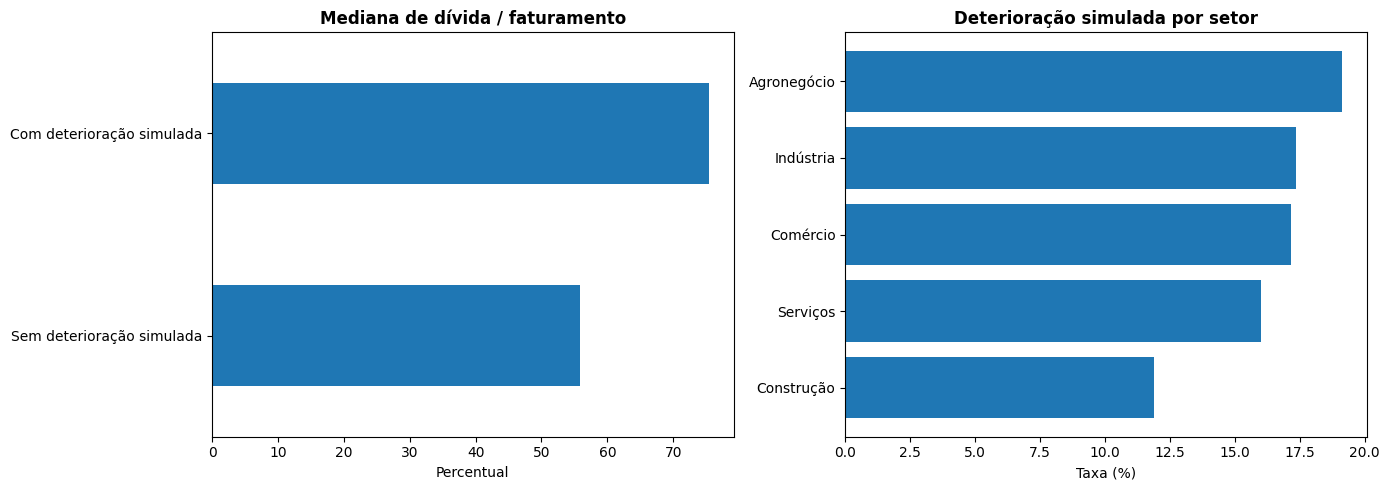

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

medianas = base.groupby("grupo_deterioracao")["divida_faturamento_pct"].median().sort_values()
medianas.plot(kind="barh", ax=axes[0])
axes[0].set_title("Mediana de dívida / faturamento")
axes[0].set_xlabel("Percentual")
axes[0].set_ylabel("")

perfil = tabela_por_grupo(base, "setor_atividade").sort_values("taxa_pct")
axes[1].barh(perfil.index, perfil["taxa_pct"])
axes[1].set_title("Deterioração simulada por setor")
axes[1].set_xlabel("Taxa (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

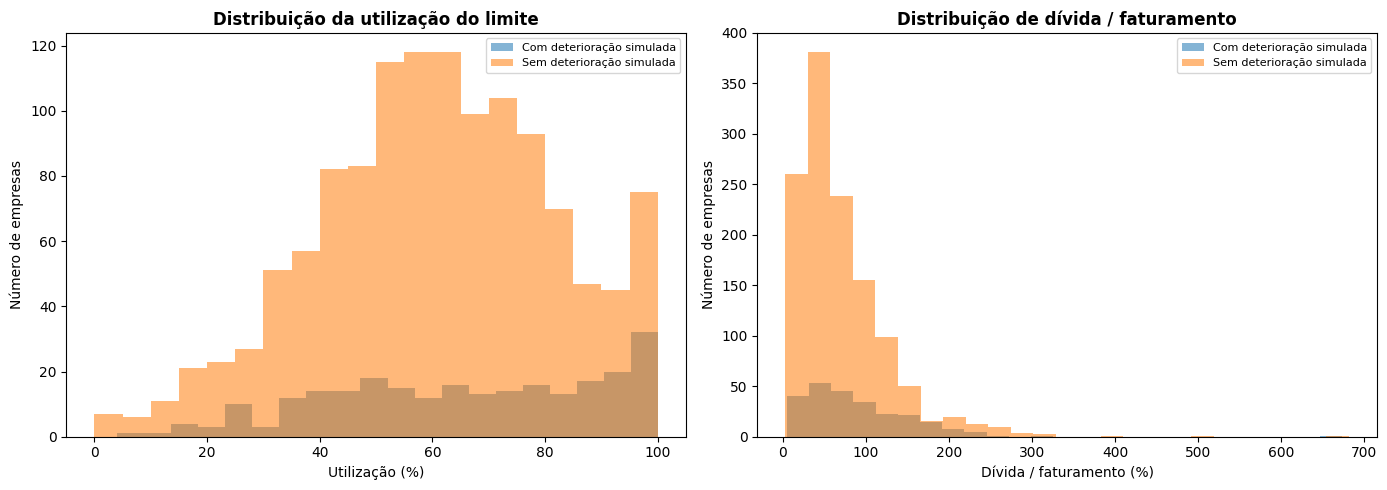

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for grupo, sub in base.groupby("grupo_deterioracao"):
    axes[0].hist(sub["utilizacao_limite_pct"].dropna(), bins=20, alpha=.55, label=grupo)
    axes[1].hist(sub["divida_faturamento_pct"].dropna(), bins=25, alpha=.55, label=grupo)
axes[0].set_title("Distribuição da utilização do limite")
axes[0].set_xlabel("Utilização (%)")
axes[1].set_title("Distribuição de dívida / faturamento")
axes[1].set_xlabel("Dívida / faturamento (%)")
for ax in axes:
    ax.set_ylabel("Número de empresas")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Conclusões automáticas e limitações

In [10]:
# As frases abaixo são montadas a partir dos resultados calculados nesta execução.
taxa_por_grupo = base.groupby("grupo_deterioracao")["divida_faturamento_pct"].median()
taxa_por_setor = tabela_por_grupo(base, "setor_atividade")
setor_maior_taxa = taxa_por_setor.index[0]
setor_menor_taxa = taxa_por_setor.index[-1]

print("PRINCIPAIS RESULTADOS DESCRITIVOS — BASE SINTÉTICA")
print(f"• Registros analisados: {len(base):,} empresas fictícias.")
print(f"• Taxa de deterioração simulada: {taxa_deterioracao:.1f}%.")
print(f"• Setor com maior taxa simulada nesta amostra: {setor_maior_taxa} ({taxa_por_setor.loc[setor_maior_taxa, 'taxa_pct']:.1f}%).")
print(f"• Setor com menor taxa simulada nesta amostra: {setor_menor_taxa} ({taxa_por_setor.loc[setor_menor_taxa, 'taxa_pct']:.1f}%).")
if "Com deterioração simulada" in taxa_por_grupo.index and "Sem deterioração simulada" in taxa_por_grupo.index:
    print(f"• Mediana dívida/faturamento — deterioração simulada: {taxa_por_grupo['Com deterioração simulada']:.1f}%.")
    print(f"• Mediana dívida/faturamento — sem deterioração simulada: {taxa_por_grupo['Sem deterioração simulada']:.1f}%.")

print("\nComo interpretar:")
print("• Os resultados descrevem apenas os dados artificiais gerados neste notebook.")
print("• As relações são parcialmente incorporadas na regra de simulação; não constituem evidência de mercado.")
print("• Associação não prova causalidade e as taxas por grupo devem ser lidas junto com as contagens.")
print("• Para uma aplicação real, seriam necessários dados autorizados, dicionário de dados e validação com especialistas.")

PRINCIPAIS RESULTADOS DESCRITIVOS — BASE SINTÉTICA
• Registros analisados: 1,500 empresas fictícias.
• Taxa de deterioração simulada: 16.5%.
• Setor com maior taxa simulada nesta amostra: Agronegócio (19.1%).
• Setor com menor taxa simulada nesta amostra: Construção (11.9%).
• Mediana dívida/faturamento — deterioração simulada: 75.4%.
• Mediana dívida/faturamento — sem deterioração simulada: 55.9%.

Como interpretar:
• Os resultados descrevem apenas os dados artificiais gerados neste notebook.
• As relações são parcialmente incorporadas na regra de simulação; não constituem evidência de mercado.
• Associação não prova causalidade e as taxas por grupo devem ser lidas junto com as contagens.
• Para uma aplicação real, seriam necessários dados autorizados, dicionário de dados e validação com especialistas.


## 9. Checklist de revisão

- [x] Base sintética reproduzível com semente fixa.
- [x] Auditoria de ausências e duplicatas.
- [x] Tratamento de dados documentado.
- [x] Razões com denominador zero tratadas como indefinidas.
- [x] Tabelas e gráficos gerados por código.
- [x] Conclusões identificadas como descritivas e sintéticas.
- [ ] Revisar o texto e a apresentação antes de publicar no GitHub.

**Competências demonstradas:** preparação de dados com `pandas`, criação de indicadores, análise exploratória, visualização e comunicação de resultados com ressalvas claras.